# IMAGO Hackathon | Additional EO data through EODH

A short guide to discovering, accessing and visualising additional Earth observation datasets through EODH. This notebook is optional supporting material.

## Dataset overview

| Dataset | Provider | Source resolution | Period |
|---|---|---|---|
| Sentinel-2 ARD | Defra/JNCC via EODH | 10 m | July 2015 onwards |
| Landsat-derived LST (EOCIS CHUK) | EOCIS/CEDA via EODH | 100 m | 2018–2022, daytime |

- **Data access:** Remote catalogue and data assets, rather than the preloaded `data/` folder.
- **Example:** A small Newcastle study area during summer 2022.
- **Limitations:** Cloud cover and unavailable retrievals may result in missing pixels.

This example uses individual observations. Seasonal composites and further analysis are left to participants.

## 1. Load

Connect to the public EODH catalogue and identify the two collections. The CEDA STAC search endpoint is used to find observations.

In [1]:
from pystac_client import Client
import rasterio
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import requests
import tempfile
from pathlib import Path

public = Client.open("https://eodatahub.org.uk/api/catalogue/stac/catalogs/public/")
ceda = public.get_child("ceda-stac-catalogue")

s2_id = "sentinel2_ard"
landsat_id = "eocis-chuk-lst"

for collection_id in [s2_id, landsat_id]:
    collection = ceda.get_collection(collection_id)
    print(collection.id, "—", collection.title)

sentinel2_ard — Sentinel 2 ARD
eocis-chuk-lst — EOCIS CHUK Land Surface Temperature


## 2. Explore

Define a study area and date range, then search both collections. The search returns up to 20 items per collection; these are candidate observations, not a guarantee of valid pixels within the study area.

In [3]:
# Newcastle bounding box: west, south, east, north (longitude/latitude)
bbox = [-1.65, 54.96, -1.60, 54.99]

# Optional: use the bounding box of your own study area boundary
# import geopandas as gpd
# aoi = gpd.read_file("path/to/study_area.shp").to_crs("EPSG:4326")
# bbox = aoi.total_bounds.tolist()

period = "2022-06-01/2022-08-31"
search_client = Client.open("https://api.stac.ceda.ac.uk/")

def find_items(collection_id):
    items = list(search_client.search(
        collections=[collection_id], bbox=bbox,
        datetime=period, max_items=20
    ).items())
    print(collection_id, "— returned items:", len(items))
    return items

s2_items = find_items(s2_id)
lst_items = find_items(landsat_id)

for item in s2_items[:5]:
    print(item.id, item.datetime, item.properties.get("eo:cloud_cover"))

for item in lst_items[:5]:
    print(item.id, item.datetime)

sentinel2_ard — returned items: 20
eocis-chuk-lst — returned items: 9
neodc.sentinel_ard.data.sentinel_2.2022.08.27.S2A_20220827_lat55lon215_T30UWF_ORB037_utm30n_osgb 2022-08-27 11:21:31+00:00 30.344442
neodc.sentinel_ard.data.sentinel_2.2022.08.27.S2A_20220827_lat55lon213_T30UWG_ORB037_utm30n_osgb 2022-08-27 11:21:31+00:00 34.859924
neodc.sentinel_ard.data.sentinel_2.2022.08.22.S2B_20220822_lat55lon215_T30UWF_ORB037_utm30n_osgb 2022-08-22 11:21:19+00:00 89.26752
neodc.sentinel_ard.data.sentinel_2.2022.08.17.S2A_20220817_lat55lon215_T30UWF_ORB037_utm30n_osgb 2022-08-17 11:21:31+00:00 16.140076
neodc.sentinel_ard.data.sentinel_2.2022.08.17.S2A_20220817_lat55lon213_T30UWG_ORB037_utm30n_osgb 2022-08-17 11:21:31+00:00 10.512109
795e202f-4771-446b-827e-ad7beefe0360 2022-08-09 12:00:00+00:00
8792f3f1-01a9-4a4b-ad21-f702db65ffa5 2022-07-31 12:00:00+00:00
51aa4b81-a14e-4f2a-ac75-ebfd268cb525 2022-07-24 12:00:00+00:00
2f26883c-a3b4-4776-a52e-b9771075dced 2022-07-15 12:00:00+00:00
0527be50-9024-

## 3. Analyse

Select one observation from each collection and inspect the information needed to read the data. For Sentinel-2, select the lowest reported scene cloud cover among the returned items. For Landsat, start with the first returned observation; change the index if coverage is poor.

### Sentinel-2 ARD

In [4]:
if not s2_items or not lst_items:
    raise ValueError("No observations for one or both collections. Change the area or dates.")

s2 = min(s2_items, key=lambda i: i.properties.get("eo:cloud_cover")
         if i.properties.get("eo:cloud_cover") is not None else 100)
lst = lst_items[0]

with rasterio.open(s2.assets["cog"].href) as src:
    print("Sentinel-2 date:", s2.datetime)
    print("Band descriptions:", src.descriptions)

Sentinel-2 date: 2022-08-12 11:21:19+00:00
Band descriptions: ('Blue', 'Green', 'Red', 'RE_B5', 'RE_B6', 'RE_B7', 'NIR_B8', 'NIR_B8A', 'SWIR1', 'SWIR2')


### Landsat LST

Download one selected NetCDF observation to a temporary file. Inspect its temperature units and coordinate system, extract the study-area bounding box and convert Kelvin to Celsius. The temporary file is removed after the subset is loaded into memory.

In [5]:
nc_asset = next(asset for asset in lst.assets.values()
                if asset.media_type == "application/netcdf")

response = requests.get(nc_asset.href, timeout=120)
response.raise_for_status()

with tempfile.TemporaryDirectory() as tmp:
    nc_path = Path(tmp) / "landsat_lst.nc"
    nc_path.write_bytes(response.content)

    with xr.open_dataset(nc_path, engine="netcdf4") as ds:
        print("Landsat date:", lst.datetime)
        print("Available variables:", list(ds.data_vars))
        print("LST units:", ds["lst"].attrs.get("units"))
        print("CRS:", ds["crsOSGB"].attrs.get("projected_crs_name"))

        xmin, ymin, xmax, ymax = transform_bounds(
            "EPSG:4326", "EPSG:27700", *bbox)
        lst_subset = ds["lst"].sel(x=slice(xmin, xmax), y=slice(ymax, ymin))
        lst_celsius = (lst_subset - 273.15).load()
        lst_celsius.attrs["units"] = "°C"

valid = int(lst_celsius.count().item())
print("Valid pixels:", valid)
print("Valid coverage (%):", round(100 * valid / lst_celsius.size, 2)
      if lst_celsius.size else 0)

Landsat date: 2022-08-09 12:00:00+00:00
Available variables: ['crsOSGB', 'x_bnds', 'y_bnds', 'lst']
LST units: K
CRS: OSGB36 / British National Grid
Valid pixels: 1056
Valid coverage (%): 100.0


## 4. Visualise

### Sentinel-2 true-colour RGB

Read only the study-area window from the Sentinel-2. The confirmed band order is Red (3), Green (2), Blue (1). Contrast stretching is applied for display only.

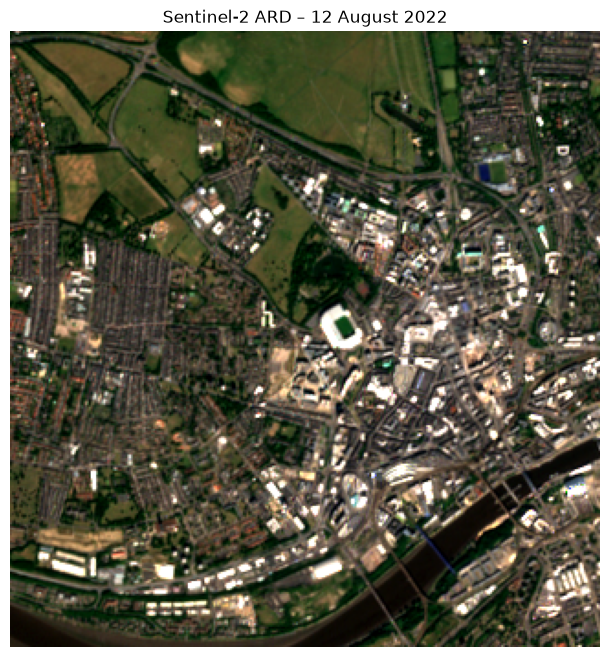

In [6]:
with rasterio.open(s2.assets["cog"].href) as src:

    # Transform the study area to the raster CRS
    bounds = transform_bounds("EPSG:4326", src.crs, *bbox)
    window = from_bounds(*bounds, transform=src.transform)

    # Read Red, Green and Blue bands
    rgb = src.read([3, 2, 1], window=window, masked=True)
    rgb = rgb.astype("float32").filled(np.nan)

# Apply a contrast stretch for display
vmin, vmax = np.nanpercentile(rgb, [2, 98])

if vmax > vmin:
    rgb = np.clip((rgb - vmin) / (vmax - vmin), 0, 1)

# Display the RGB image
plt.figure(figsize=(8, 8))
plt.imshow(np.moveaxis(rgb, 0, -1))
plt.title(f"Sentinel-2 ARD – {s2.datetime:%d %B %Y}")
plt.axis("off")
plt.show()


### Landsat land surface temperature

Visualise daytime land surface temperature at 100 m resolution
for the selected observation. Missing pixels may occur due to
cloud cover or unavailable retrievals.

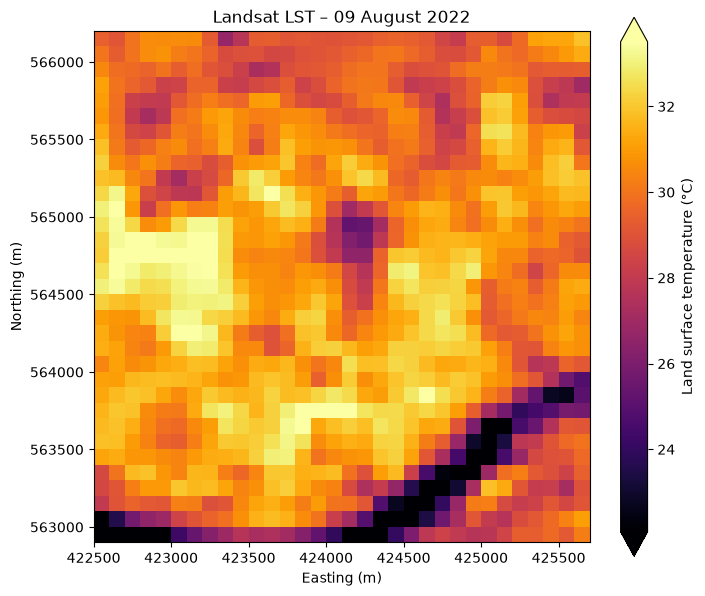

In [7]:
if lst_celsius.count().item() > 0:

    plt.figure(figsize=(8, 7))

    lst_celsius.plot(
        cmap="inferno",
        robust=True,
        cbar_kwargs={"label": "Land surface temperature (°C)"}
    )

    plt.title(f"Landsat LST – {lst.datetime:%d %B %Y}")
    plt.xlabel("Easting (m)")
    plt.ylabel("Northing (m)")
    plt.gca().set_aspect("equal")
    plt.show()

else:
    print("No valid LST pixels for this date and study area.")
    print("Try another available observation.")


## References

- [EODH discovery walkthrough](https://docs.eodatahub.org.uk/training-materials/walkthrough/1_202502_discovery/)
- [EODH catalogue navigation](https://docs.eodatahub.org.uk/training-materials/examples/pyeodh-vs-pystac/)
- [EODH Sentinel-2 ARD examples](https://docs.eodatahub.org.uk/training-materials/examples/datacubes/)

The saved maps are example outputs from the original EODH test run. Run the notebook from top to bottom to reproduce them. Remote availability and returned observations may change.